# Thực nghiệm XJTU
Lishen NCM 2 Ah, Batch-1/2. Kết quả tách riêng SDU; loại chu kỳ tham chiếu đầu khỏi đánh giá chính.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reports/xjtu/features.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
from battery_soh.xjtu import normalized_features
from sklearn.ensemble import RandomForestRegressor
folder = ROOT / "reports/xjtu"
info = json.loads((folder / "dataset_summary.json").read_text())
print(json.dumps(info, ensure_ascii=False, indent=2))

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-5k7kv03h because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


{
  "dataset": "XJTU Batch-1/2",
  "source": "https://zenodo.org/records/10963339",
  "license": "cc-by-4.0",
  "batteries": 23,
  "available_source_batteries": 55,
  "selected_batches": [
    1,
    2
  ],
  "raw_points": 46215511,
  "source_cycles": 6961,
  "valid_cycles": 6961,
  "excluded_cycles": 0,
  "nominal_capacity_ah": 2.0,
  "soh_definition": "summary.discharge_capacity_Ah / 2.0 * 100; no clipping",
  "window_seconds": 120,
  "time_policy": "system_time; duplicate seconds averaged only in derived window",
  "duplicate_window_seconds_aggregated": 59,
  "features_sha256": "c20caab44f6efee49750d16bb0e2f85f8fa804ce059c01db90f64cbbf37a1188",
  "scope": "Laboratory Lishen 18650 NCM; fixed-protocol Batch-1/2 selected before evaluation. Not vehicle BMS. Raw MAT preserved."
}


## 1. Dữ liệu và nhãn
Nhãn theo dung lượng danh định, không đưa dung lượng đo vào đặc trưng.

In [2]:
data = pd.read_csv(folder / "features.csv")
data = data.loc[data.cycle > 1].reset_index(drop=True)
assert (abs(data.soh_pct - data.capacity_ah / 2 * 100) < 1e-8).all()
display(data.groupby("batch").agg(pins=("battery","nunique"), cycles=("cycle","size"), soh_min=("soh_pct","min"), soh_max=("soh_pct","max")))
display(pd.read_csv(folder / "data_audit.csv"))

,pins,cycles,soh_min,soh_max
batch,,,,
1,8,3211,79.05,98.7
2,15,3727,79.70,99.2


,battery,batch,source_cycles,raw_points,valid_cycles,excluded_cycles,duplicate_window_seconds_aggregated
0,XJTU_B1_01,1,390,2702101,390,0,0
1,XJTU_B1_02,1,407,2812247,407,0,1
2,XJTU_B1_03,1,393,2705157,393,0,2
3,XJTU_B1_04,1,396,2753754,396,0,0
4,XJTU_B1_05,1,403,2805918,403,0,2
5,XJTU_B1_06,1,408,2831614,408,0,2
6,XJTU_B1_07,1,402,2801165,402,0,2
7,XJTU_B1_08,1,420,2930844,420,0,2
8,XJTU_B2_01,2,299,1873265,299,0,0
9,XJTU_B2_10,2,164,1076912,164,0,0


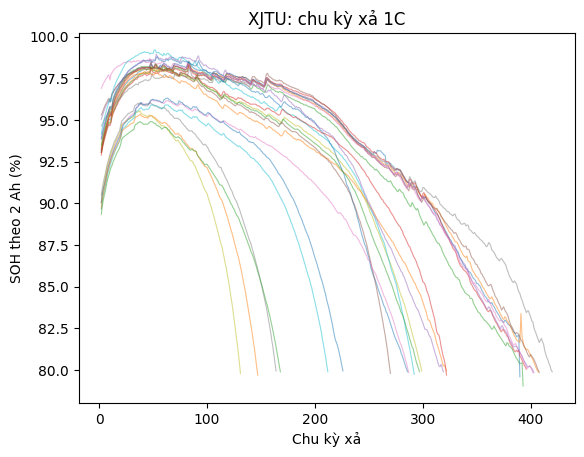

In [3]:
for battery, part in data.groupby("battery"):
    plt.plot(part.cycle, part.soh_pct, alpha=.5, linewidth=.8)
plt.xlabel("Chu kỳ xả"); plt.ylabel("SOH theo 2 Ah (%)"); plt.title("XJTU: chu kỳ xả 1C")
plt.show()

## 2. Kiểm tra giữ riêng pin và chạy lại RF một vòng
Chỉ dùng pin thuộc tập học. Đây là chạy lại cấu hình cố định, không tìm tham số bằng test.

In [4]:
split = pd.read_csv(folder / "split_assignments.csv").set_index("battery").test_fold
folds = data.battery.map(split)
train, test = folds != 1, folds == 1
assert set(data.loc[train,"battery"]).isdisjoint(data.loc[test,"battery"])
X = normalized_features(data, 2.0)
assert "capacity_ah" not in X and "soh_pct" not in X
model = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_depth=16, max_samples=.7, random_state=42, n_jobs=2)
model.fit(X.loc[train], data.loc[train,"soh_pct"])
from sklearn.metrics import mean_absolute_error
print("MAE gộp chu kỳ vòng 1 (khác trung bình theo pin):", mean_absolute_error(data.loc[test,"soh_pct"], model.predict(X.loc[test])))

MAE gộp chu kỳ vòng 1 (khác trung bình theo pin): 0.40963712673550107


## 3. So sánh mô hình và kiểm tra chuyển miền
MAE/RMSE theo điểm phần trăm SOH; bảng tổng hợp lấy trung bình theo pin.

In [5]:
scores = pd.read_csv(folder / "metrics_summary.csv")
display(scores)
display(pd.read_csv(folder / "paired_multi_source.csv"))

,design,model,mae,rmse,r2
0,XJTU held-out,Mean baseline,3.759173,4.719719,-0.056588
1,XJTU held-out,Ridge,0.971426,1.204706,0.920035
2,XJTU held-out,Random Forest,0.576849,0.764228,0.964807
3,XJTU held-out,LightGBM,0.595795,0.786766,0.963744
4,XJTU held-out,Ridge-RF residual,0.666386,0.827641,0.959676
5,XJTU held-out,RF multi-source,0.623454,0.866767,0.944650
6,XJTU held-out,GRU,1.240253,1.543185,0.856380
7,SDU to XJTU,RF normalized,42.654311,42.909727,-89.594706
8,SDU to XJTU,RF original SDU,12.836131,13.648876,-8.044720
9,Held-out batch 1,Random Forest,1.237341,1.604088,0.890376


,battery,mae_multi_minus_single_pp
0,XJTU_B1_01,0.011597
1,XJTU_B1_02,-0.003215
2,XJTU_B1_03,0.004057
3,XJTU_B1_04,-0.002669
4,XJTU_B1_05,0.017443
5,XJTU_B1_06,-0.011244
6,XJTU_B1_07,-0.006157
7,XJTU_B1_08,-0.012589
8,XJTU_B2_01,0.003371
9,XJTU_B2_02,-0.008073


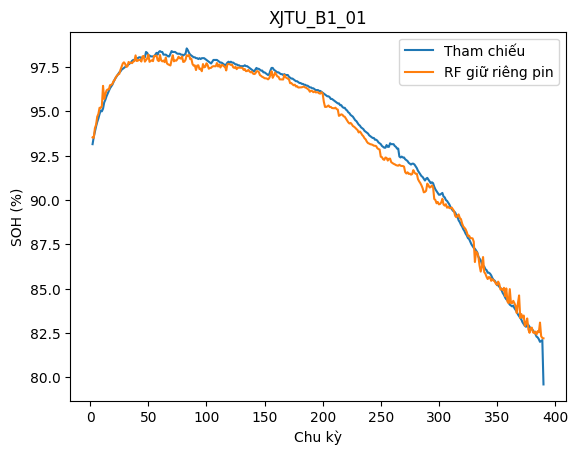

In [6]:
pred = pd.read_csv(folder / "predictions.csv")
part = pred[(pred.design == "XJTU held-out") & (pred.model == "Random Forest")]
battery = sorted(part.battery.unique())[0]
part = part[part.battery == battery].sort_values("cycle")
plt.plot(part.cycle, part.actual_soh, label="Tham chiếu")
plt.plot(part.cycle, part.predicted_soh, label="RF giữ riêng pin")
plt.title(battery); plt.xlabel("Chu kỳ"); plt.ylabel("SOH (%)"); plt.legend(); plt.show()

## Giới hạn
Dữ liệu lab, khác dòng xả SDU; chưa có kiểm chứng trên xe và RUL. Artifact ứng dụng refit không được dùng thay điểm pin giữ riêng.